<a href="https://colab.research.google.com/github/srushtisatav07/GitHub-practical-test/blob/main/Copy_of_House_Price_EDA_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving train.csv to train.csv


In [ ]:

# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("All libraries imported successfully!")


All libraries imported successfully!


All libraries imported successfully!

In [ ]:

# Loading the house price dataset

df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [ ]:

# Checking the number of rows and columns

print("Shape of dataset:", df.shape)

# Displaying the first five rows

df.head()


Shape of dataset: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:

# Understanding the dataset

print("DATASET INFORMATION")

df.info()


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   i

In [ ]:

# Checking missing values in each column

missing_values = df.isnull().sum()

print(missing_values[missing_values > 0].sort_values(ascending=False))


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [ ]:

# Calculating missing value percentages

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_summary = missing_summary[missing_summary["Missing Values"] > 0]

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_summary


,Missing Values,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


In [ ]:

# Classifying variables

# Numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Categorical columns
categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("Total Numerical Columns:", len(numeric_cols))
print("Total Categorical Columns:", len(categorical_cols))

print("\nNumerical Columns:")
print(numeric_cols)

print("\nCategorical Columns:")
print(categorical_cols)


Total Numerical Columns: 38
Total Categorical Columns: 43

Numerical Columns:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'Centra

In [ ]:

# Identifying ordinal variables

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

for column, order in ordinal_map.items():
    df[column] = pd.Categorical(
        df[column],
        categories=order,
        ordered=True
    )

print("Ordinal variables identified successfully!")

print("OverallQual is also an ordinal variable (1 to 10).")


Ordinal variables identified successfully!
OverallQual is also an ordinal variable (1 to 10).


In [ ]:

# Basic descriptive statistics

df.describe()


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:

# Calculating descriptive statistics

columns = ["SalePrice", "GrLivArea", "LotArea"]

for column in columns:
    print("\nStatistics for:", column)

    print("Mean:", df[column].mean())
    print("Median:", df[column].median())
    print("Mode:", df[column].mode()[0])
    print("Standard Deviation:", df[column].std())
    print("Variance:", df[column].var())
    print("Range:", df[column].max() - df[column].min())
    print("IQR:", df[column].quantile(0.75) - df[column].quantile(0.25))
    print("Skewness:", df[column].skew())
    print("Kurtosis:", df[column].kurt())



Statistics for: SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529

Statistics for: GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174

Statistics for: LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033


In [ ]:

# Analysing categorical variables

for column in ["Neighborhood", "HouseStyle"]:
    print("\nValue counts for:", column)
    print(df[column].value_counts())

    print("Mode:", df[column].mode()[0])




Value counts for: Neighborhood
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64
Mode: NAmes

Value counts for: HouseStyle
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64
Mode: 1Story


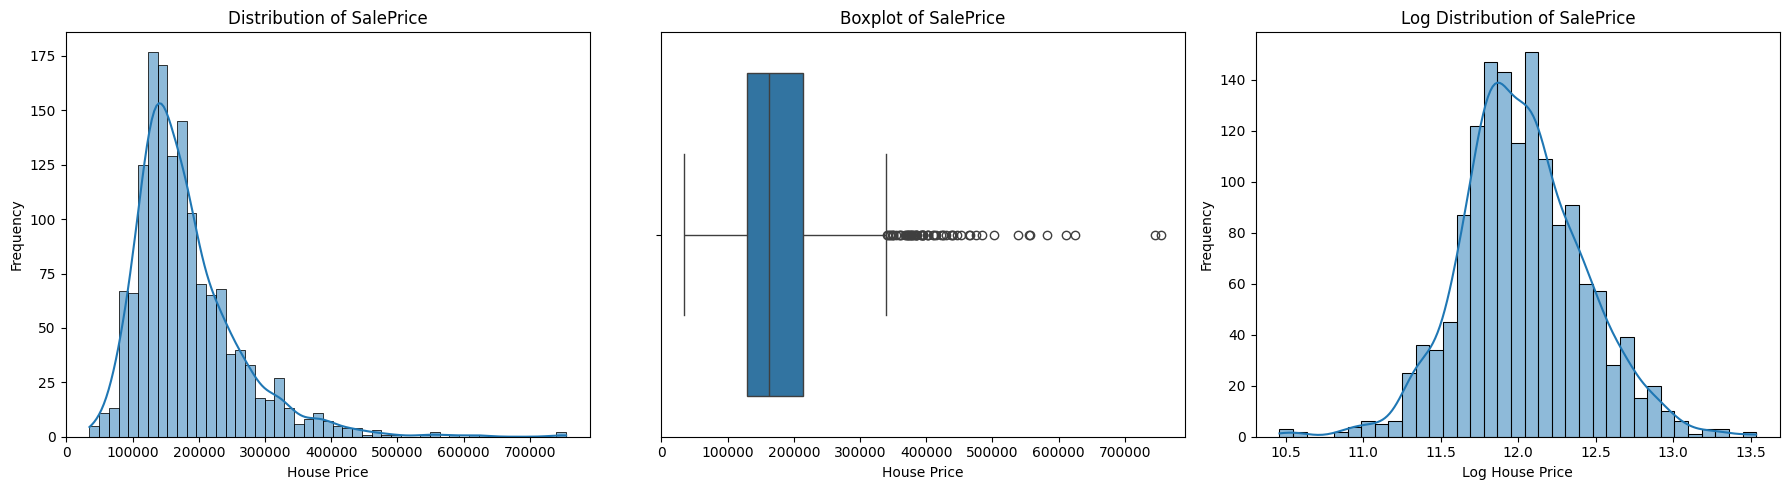

In [ ]:

# Distribution of House Prices

plt.figure(figsize=(18, 5))

# First graph: Histogram
plt.subplot(1, 3, 1)
sns.histplot(df["SalePrice"], kde=True)
plt.title("Distribution of SalePrice")
plt.xlabel("House Price")
plt.ylabel("Frequency")

# Second graph: Boxplot
plt.subplot(1, 3, 2)
sns.boxplot(x=df["SalePrice"])
plt.title("Boxplot of SalePrice")
plt.xlabel("House Price")

# Third graph: Log Histogram
plt.subplot(1, 3, 3)
sns.histplot(np.log1p(df["SalePrice"]), kde=True)
plt.title("Log Distribution of SalePrice")
plt.xlabel("Log House Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


### Observation – Distribution of SalePrice

1. The SalePrice distribution is positively skewed (right-skewed).
2. Most houses have prices concentrated in the lower-to-middle price range.
3. The boxplot identifies several high-price outliers.
4. After applying log transformation using `np.log1p()`, the distribution becomes more symmetrical.
5. Log transformation helps reduce the effect of extreme values.

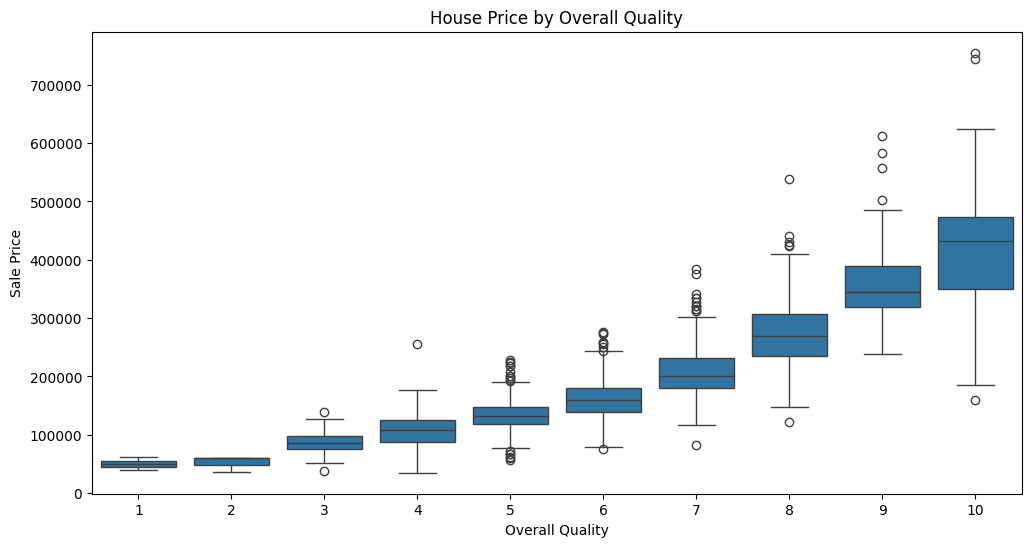

In [ ]:

# House Price Analysis by Quality and Neighborhood

plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x="OverallQual", y="SalePrice")

plt.title("House Price by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()


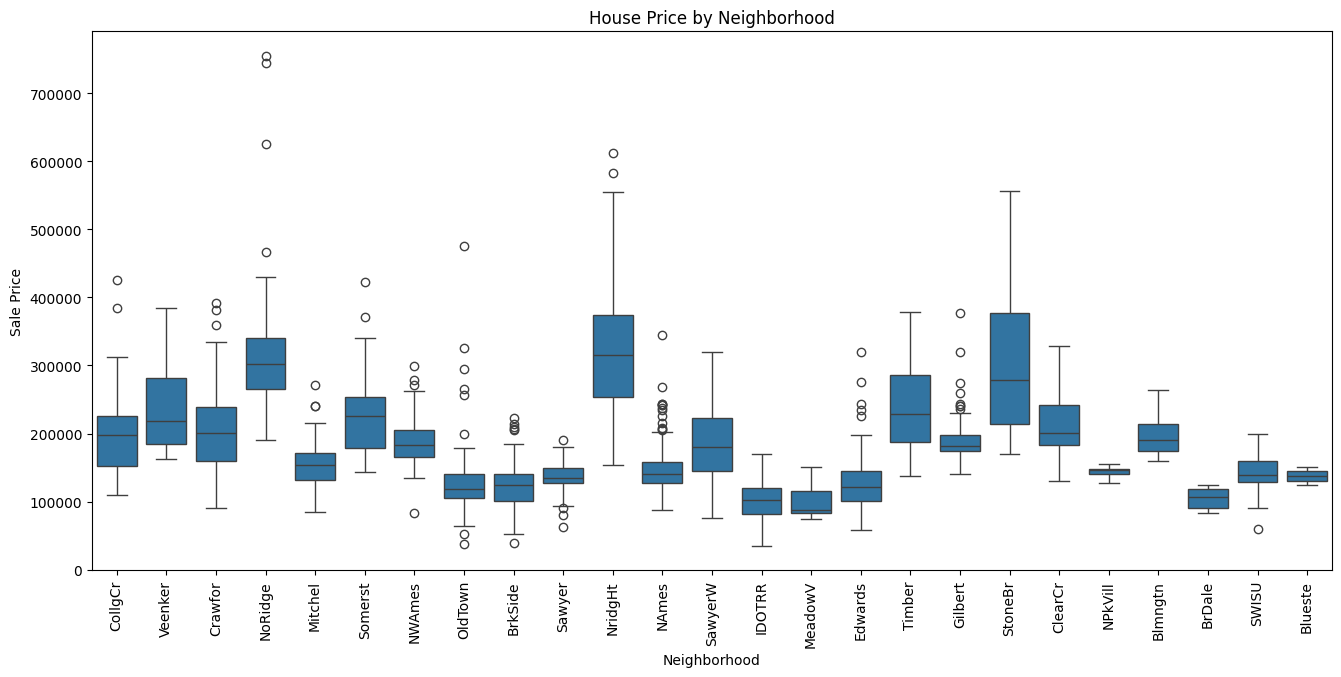

In [ ]:

# House Price Analysis by Neighborhood

plt.figure(figsize=(16, 7))

sns.boxplot(data=df, x="Neighborhood", y="SalePrice")

plt.title("House Price by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price")

plt.xticks(rotation=90)
plt.show()


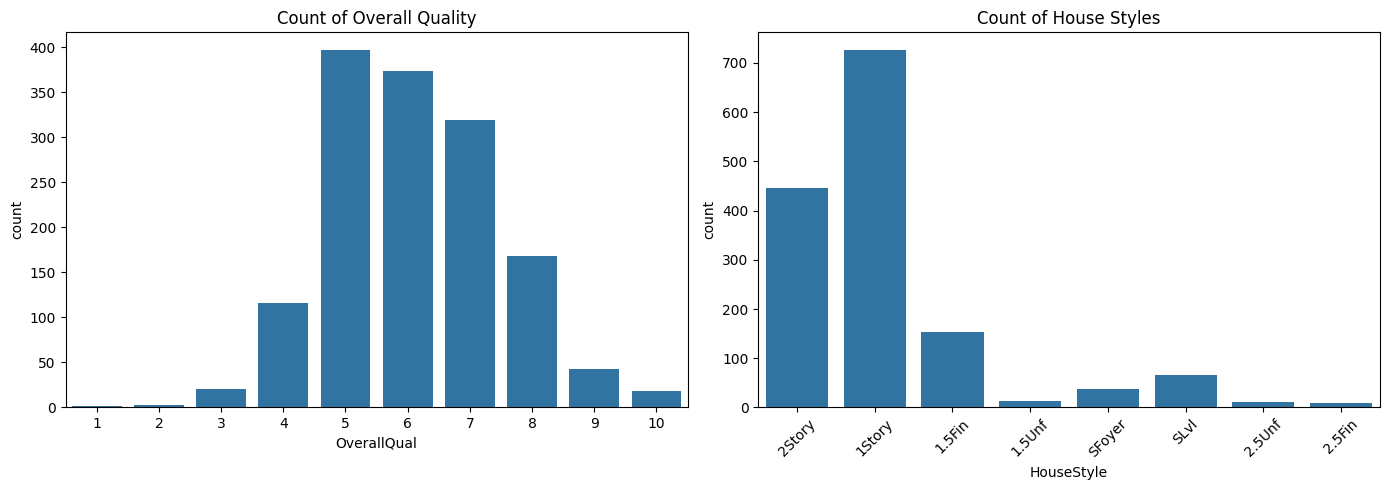

In [ ]:

# Countplot of Overall Quality and House Style

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x="OverallQual")
plt.title("Count of Overall Quality")

plt.subplot(1, 2, 2)
sns.countplot(data=df, x="HouseStyle")
plt.title("Count of House Styles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


### Observations – Countplots

1. Overall Quality: Most houses have an overall quality rating of 5, followed by 6 and 7.
2. House Style: The 1Story house style is the most common, followed by 2Story.
3. The dataset contains fewer houses with very low or very high quality ratings.
4. The distribution shows that some house styles are much more common than others.

In [ ]:

# Correlation Analysis

correlation = df.select_dtypes(include=np.number).corr()

print("Correlation with SalePrice:")

print(correlation["SalePrice"].sort_values(ascending=False))


Correlation with SalePrice:
SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbv

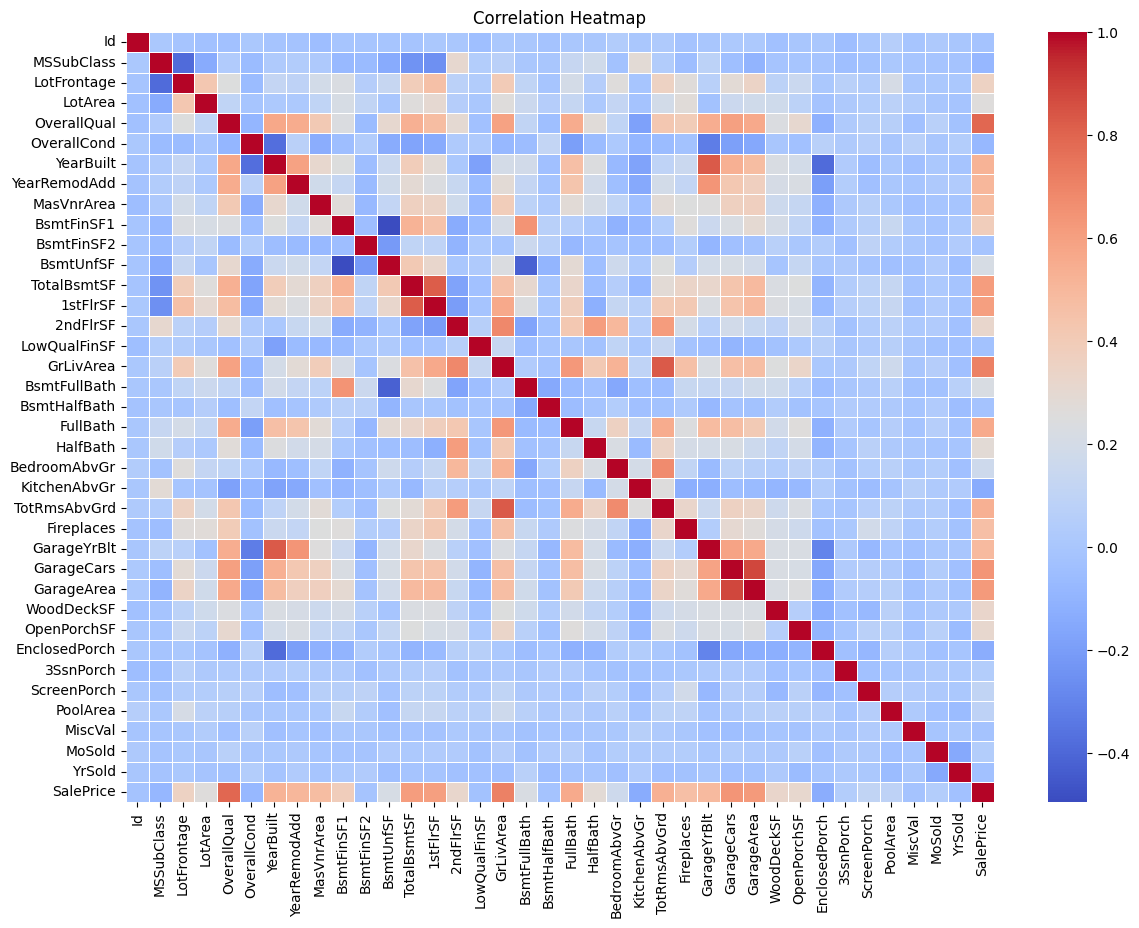

In [ ]:

# Correlation Heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False,
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()


In [ ]:

# Covariance Analysis

covariance = df.select_dtypes(include=np.number).cov()

print("Covariance with SalePrice:")

print(covariance["SalePrice"].sort_values(ascending=False))


Covariance with SalePrice:
SalePrice        6.311111e+09
LotArea          2.092111e+08
GrLivArea        2.958187e+07
TotalBsmtSF      2.138442e+07
1stFlrSF         1.860663e+07
BsmtFinSF1       1.400137e+07
2ndFlrSF         1.107415e+07
GarageArea       1.058910e+07
BsmtUnfSF        7.528864e+06
MasVnrArea       6.854858e+06
WoodDeckSF       3.230258e+06
OpenPorchSF      1.662523e+06
YearBuilt        1.254637e+06
GarageYrBlt      9.489296e+05
YearRemodAdd     8.317079e+05
LotFrontage      7.124262e+05
ScreenPorch      4.936535e+05
PoolArea         2.949323e+05
3SsnPorch        1.038372e+05
OverallQual      8.690413e+04
TotRmsAbvGrd     6.891717e+04
GarageCars       3.802018e+04
FullBath         2.453808e+04
Fireplaces       2.391325e+04
HalfBath         1.135024e+04
BedroomAbvGr     1.090147e+04
MoSold           9.972849e+03
BsmtFullBath     9.362786e+03
BsmtHalfBath    -3.194849e+02
KitchenAbvGr    -2.378952e+03
YrSold          -3.051541e+03
OverallCond     -6.882739e+03
LowQualFinSF 

In [ ]:

# Finding Top 10 Features Correlated with SalePrice

corr_matrix = df.select_dtypes(include=np.number).corr()
cov_matrix = df.select_dtypes(include=np.number).cov()

top_10 = (
    corr_matrix["SalePrice"]
    .drop("SalePrice")
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

top_10_values = corr_matrix.loc[top_10.index, "SalePrice"]

print("Top 10 Features Correlated with SalePrice:")
print(top_10_values)


Top 10 Features Correlated with SalePrice:
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


In [ ]:

# Comparing Correlation and Covariance for Top 3 Features

top_3 = top_10.index[:3]

for feature in top_3:
    print("\nFeature:", feature)
    print("Correlation:", corr_matrix.loc[feature, "SalePrice"])
    print("Covariance:", cov_matrix.loc[feature, "SalePrice"])



Feature: OverallQual
Correlation: 0.7909816005838053
Covariance: 86904.12583679946

Feature: GrLivArea
Correlation: 0.7086244776126515
Covariance: 29581866.743236575

Feature: GarageCars
Correlation: 0.6404091972583519
Covariance: 38020.18135897172


In [ ]:

# Finding Top 10 Features Correlated with SalePrice

corr_matrix = df.select_dtypes(include=np.number).corr()

top_10 = (
    corr_matrix["SalePrice"]
    .drop("SalePrice")
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Features Correlated with SalePrice:")
print(corr_matrix.loc[top_10.index, "SalePrice"])


Top 10 Features Correlated with SalePrice:
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64



## Step 6: Scatter Plot Analysis

Scatter plots help us understand the relationship between house features and SalePrice.

We will analyse:
1. GrLivArea vs SalePrice
2. TotalBsmtSF vs SalePrice
3. YearBuilt vs SalePrice


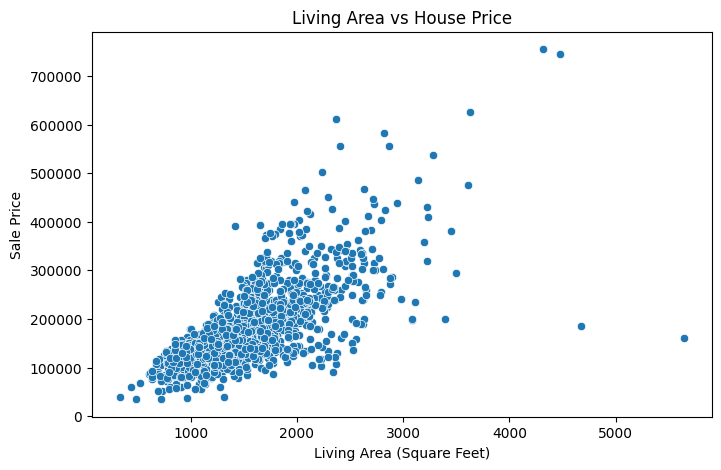

In [ ]:

# Scatter Plot: Living Area vs Sale Price

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs House Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Sale Price")

plt.show()


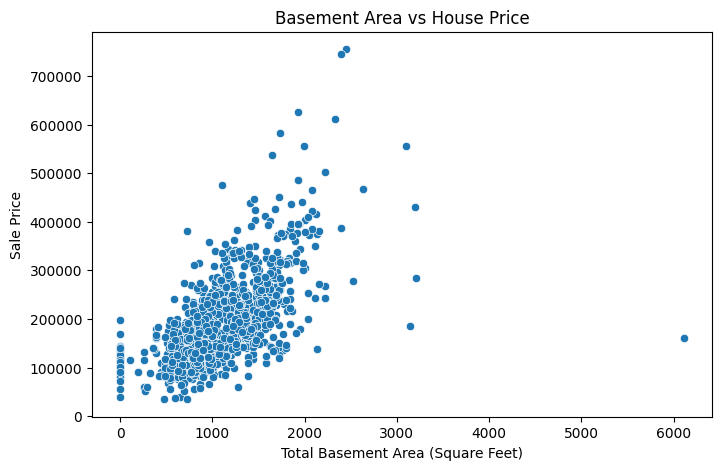

In [ ]:

# Scatter Plot: Basement Area vs Sale Price

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="TotalBsmtSF",
    y="SalePrice"
)

plt.title("Basement Area vs House Price")
plt.xlabel("Total Basement Area (Square Feet)")
plt.ylabel("Sale Price")

plt.show()


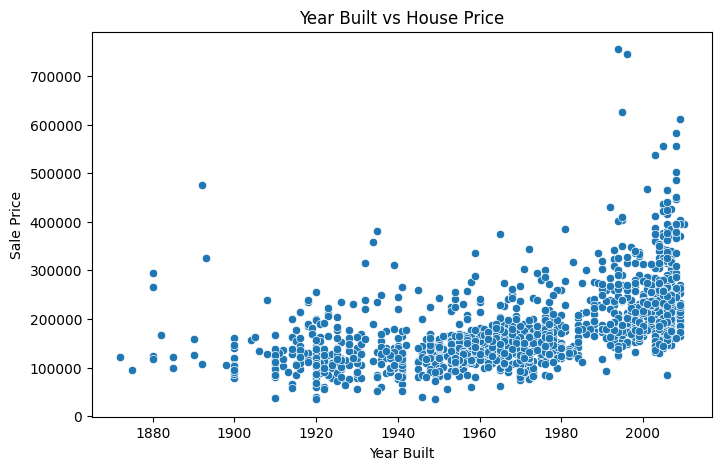

In [ ]:

# Scatter Plot: Year Built vs Sale Price

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="YearBuilt",
    y="SalePrice"
)

plt.title("Year Built vs House Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")

plt.show()


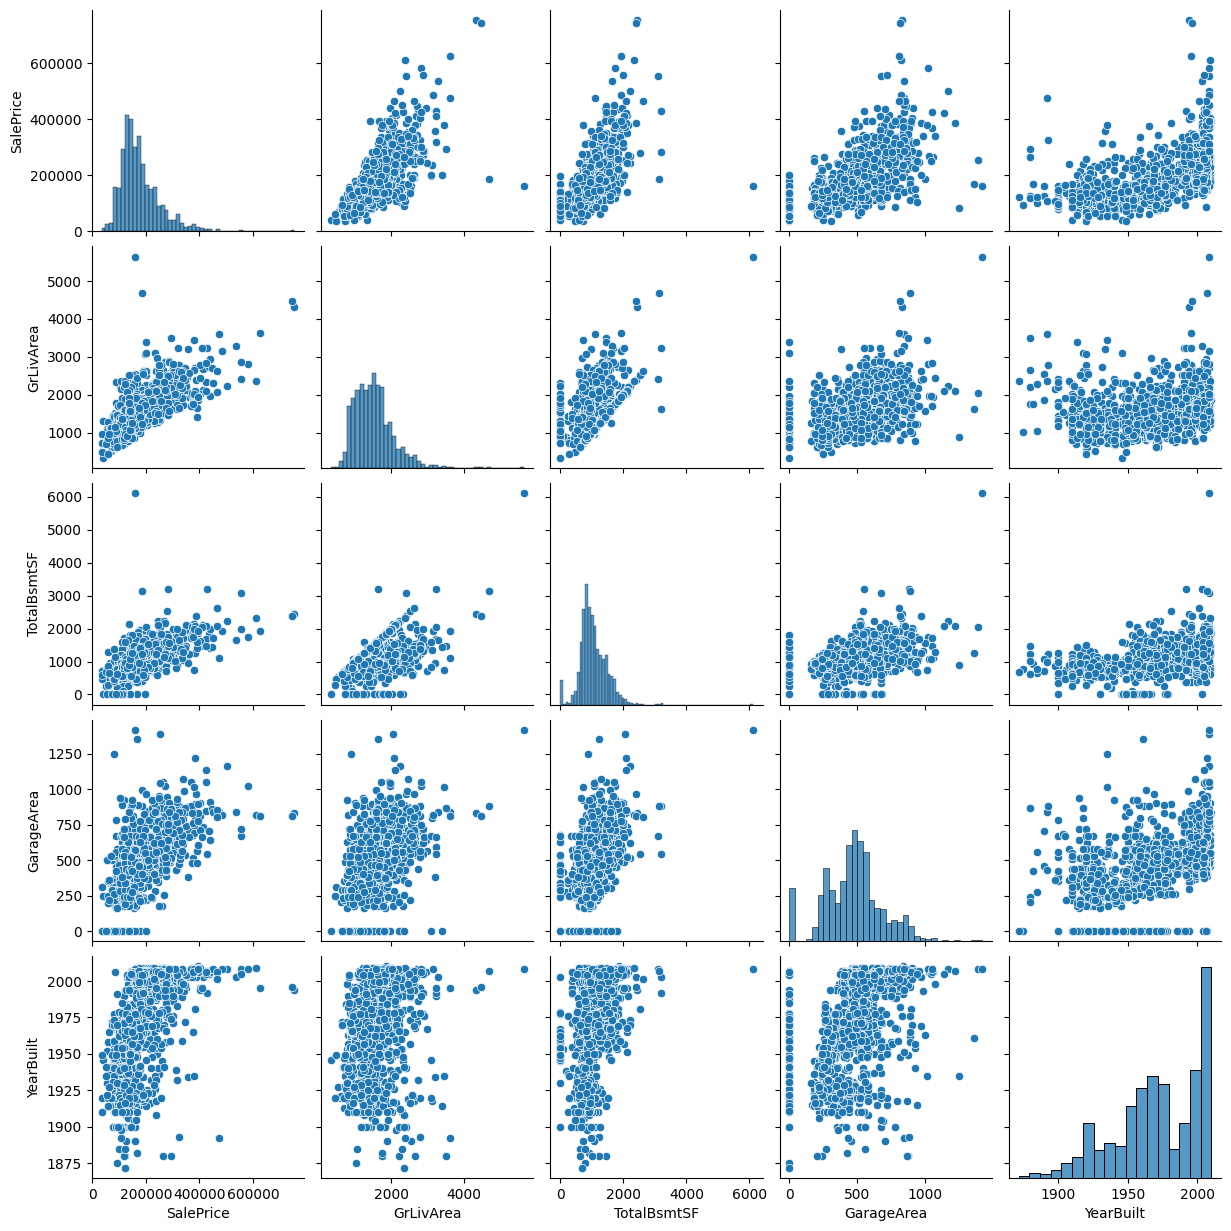

In [ ]:

# Pair Plot Analysis

selected_columns = [
    "SalePrice",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageArea",
    "YearBuilt"
]

sns.pairplot(df[selected_columns])

plt.show()


In [ ]:

# Step 8: Outlier Detection

# IQR Method
def iqr_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return series[(series < lower) | (series > upper)].index


# Z-Score Method
def zscore_outliers(series):
    mean = series.mean()
    std = series.std()

    z = (series - mean) / std

    return series[abs(z) > 3].index


# Check outliers in both columns
for column in ["GrLivArea", "SalePrice"]:

    data = df[column].dropna()

    iqr_result = iqr_outliers(data)
    zscore_result = zscore_outliers(data)

    print("\nColumn:", column)
    print("IQR Outliers:", len(iqr_result))
    print("Z-Score Outliers:", len(zscore_result))
    print("Common Outliers:", len(set(iqr_result) & set(zscore_result)))



Column: GrLivArea
IQR Outliers: 31
Z-Score Outliers: 16
Common Outliers: 16

Column: SalePrice
IQR Outliers: 61
Z-Score Outliers: 22
Common Outliers: 22


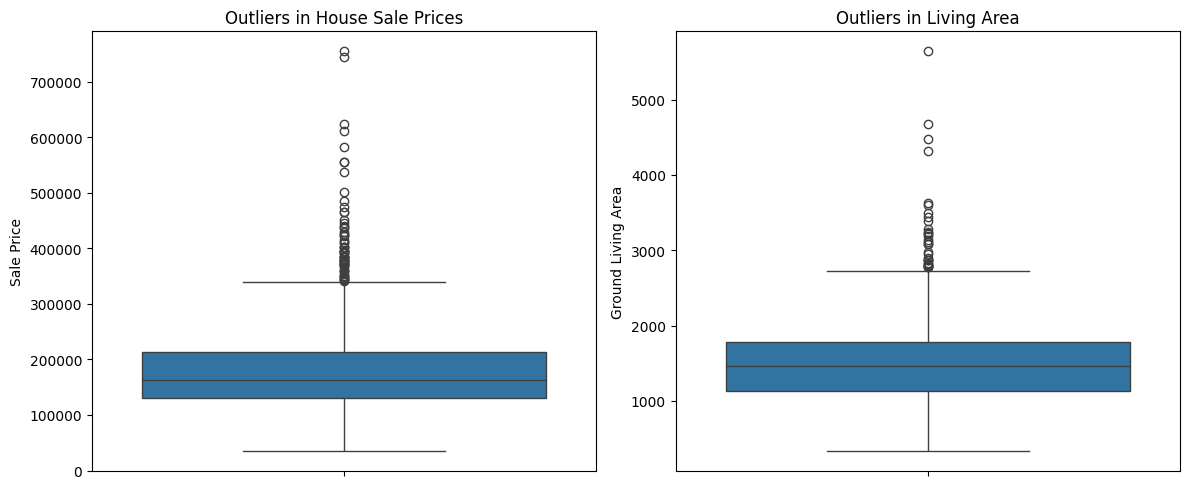

In [ ]:

# Step 9: Visualizing Outliers

plt.figure(figsize=(12, 5))

# Boxplot of SalePrice
plt.subplot(1, 2, 1)
sns.boxplot(y=df["SalePrice"])
plt.title("Outliers in House Sale Prices")
plt.ylabel("Sale Price")

# Boxplot of GrLivArea
plt.subplot(1, 2, 2)
sns.boxplot(y=df["GrLivArea"])
plt.title("Outliers in Living Area")
plt.ylabel("Ground Living Area")

plt.tight_layout()
plt.show()


In [ ]:

# Step 10: Final Project Summary

print("========== HOUSE PRICE EDA PROJECT ==========")

print("\n1. Dataset Information")
print("Total Houses:", df.shape[0])
print("Total Features:", df.shape[1])

print("\n2. Average House Price")
print(df["SalePrice"].mean())

print("\n3. Minimum House Price")
print(df["SalePrice"].min())

print("\n4. Maximum House Price")
print(df["SalePrice"].max())

print("\n5. Average Overall Quality")
print(df["OverallQual"].mean())

print("\n6. Top 5 Features Affecting House Price")
print(top_10.head(5))

print("\n========== PROJECT COMPLETED ==========")


========== HOUSE PRICE EDA PROJECT ==========

1. Dataset Information
Total Houses: 1460
Total Features: 81

2. Average House Price
180921.19589041095

3. Minimum House Price
34900

4. Maximum House Price
755000

5. Average Overall Quality
6.0993150684931505

6. Top 5 Features Affecting House Price
OverallQual    0.790982
GrLivArea      0.708624
GarageCars     0.640409
GarageArea     0.623431
TotalBsmtSF    0.613581
Name: SalePrice, dtype: float64

========== PROJECT COMPLETED ==========


## Conclusion

In this project, Exploratory Data Analysis (EDA) was performed on the House Prices dataset.

The analysis helped us understand the dataset, identify missing values, examine outliers and explore relationships between different house features and their selling prices.

### Key Findings

1. Overall Quality has a strong positive correlation with Sale Price.
2. Ground Living Area is another important factor affecting house prices.
3. Garage Cars and Garage Area also show positive relationships with Sale Price.
4. The dataset contains missing values in several columns.
5. House prices vary across different neighbourhoods.
6. The distribution of Sale Price is right-skewed.

### Final Result

EDA helped identify important patterns, relationships and factors that influence house prices. Data visualization made the dataset easier to understand and interpret.

**The project successfully demonstrates the use of Python, NumPy, Pandas, Matplotlib and Seaborn for Exploratory Data Analysis.**

In [ ]:

# Step 11: Data Quality Checks

# 1. Check duplicate rows
dup_count = df.duplicated().sum()

print("Number of duplicate rows:", dup_count)

# 2. Check categorical columns
categorical_cols = df.select_dtypes(
    include=["object"]
).columns

for col in categorical_cols:
    print("\nColumn:", col)
    print(df[col].dropna().unique()[:10])

# 3. Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

# 4. Check impossible values
print("\nNegative area values:")
print((df.select_dtypes(include=np.number) < 0).sum())

print("\nYearBuilt greater than YrSold:")
print((df["YearBuilt"] > df["YrSold"]).sum())


Number of duplicate rows: 0

Column: MSZoning
['RL' 'RM' 'C (all)' 'FV' 'RH']

Column: Street
['Pave' 'Grvl']

Column: Alley
['Grvl' 'Pave']

Column: LotShape
['Reg' 'IR1' 'IR2' 'IR3']

Column: LandContour
['Lvl' 'Bnk' 'Low' 'HLS']

Column: Utilities
['AllPub' 'NoSeWa']

Column: LotConfig
['Inside' 'FR2' 'Corner' 'CulDSac' 'FR3']

Column: LandSlope
['Gtl' 'Mod' 'Sev']

Column: Neighborhood
['CollgCr' 'Veenker' 'Crawfor' 'NoRidge' 'Mitchel' 'Somerst' 'NWAmes'
 'OldTown' 'BrkSide' 'Sawyer']

Column: Condition1
['Norm' 'Feedr' 'PosN' 'Artery' 'RRAe' 'RRNn' 'RRAn' 'PosA' 'RRNe']

Column: Condition2
['Norm' 'Artery' 'RRNn' 'Feedr' 'PosN' 'PosA' 'RRAn' 'RRAe']

Column: BldgType
['1Fam' '2fmCon' 'Duplex' 'TwnhsE' 'Twnhs']

Column: HouseStyle
['2Story' '1Story' '1.5Fin' '1.5Unf' 'SFoyer' 'SLvl' '2.5Unf' '2.5Fin']

Column: RoofStyle
['Gable' 'Hip' 'Gambrel' 'Mansard' 'Flat' 'Shed']

Column: RoofMatl
['CompShg' 'WdShngl' 'Metal' 'WdShake' 'Membran' 'Tar&Grv' 'Roll'
 'ClyTile']

Column: Exterior1

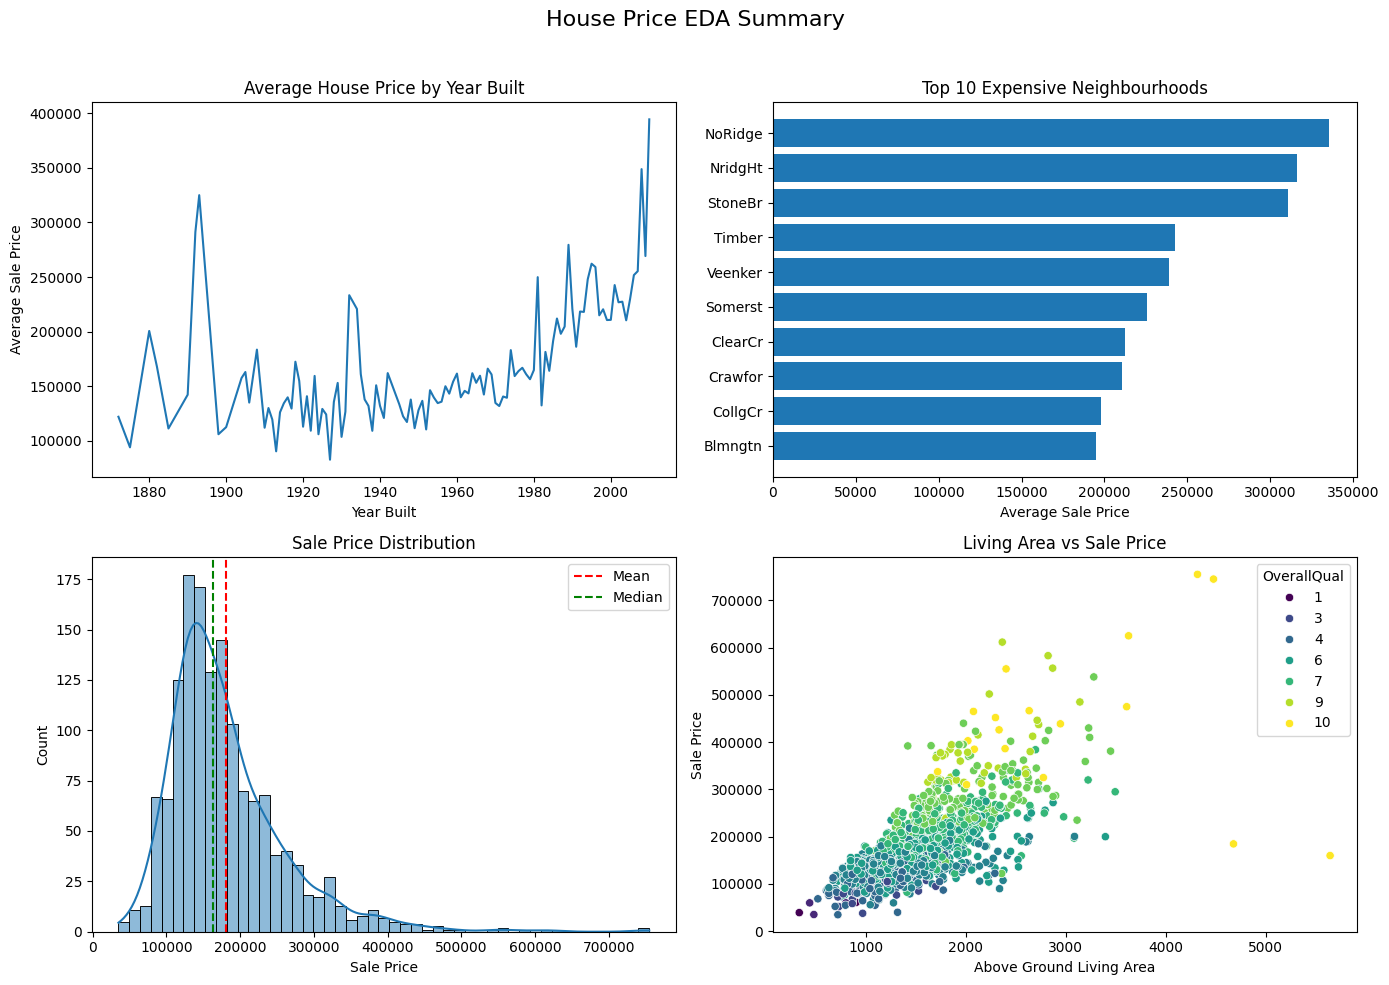

In [ ]:

# Step 12: Final EDA Dashboard

import matplotlib.pyplot as plt
import seaborn as sns

# Create a dashboard with 4 graphs
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Average House Price by Year Built
year_price = df.groupby("YearBuilt")["SalePrice"].mean()

axes[0, 0].plot(year_price.index, year_price.values)
axes[0, 0].set_title("Average House Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Sale Price")

# 2. Top 10 Neighbourhoods by Average House Price
neighbourhood_price = (
    df.groupby("Neighborhood")["SalePrice"]
    .mean()
    .nlargest(10)
    .sort_values()
)

axes[0, 1].barh(
    neighbourhood_price.index,
    neighbourhood_price.values
)
axes[0, 1].set_title("Top 10 Expensive Neighbourhoods")
axes[0, 1].set_xlabel("Average Sale Price")

# 3. Sale Price Distribution
sns.histplot(
    df["SalePrice"],
    kde=True,
    ax=axes[1, 0]
)

mean_price = df["SalePrice"].mean()
median_price = df["SalePrice"].median()

axes[1, 0].axvline(
    mean_price, color="red", linestyle="--",
    label="Mean"
)
axes[1, 0].axvline(
    median_price, color="green", linestyle="--",
    label="Median"
)

axes[1, 0].set_title("Sale Price Distribution")
axes[1, 0].set_xlabel("Sale Price")
axes[1, 0].legend()

# 4. Living Area vs Sale Price
sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    hue="OverallQual",
    palette="viridis",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Living Area vs Sale Price")
axes[1, 1].set_xlabel("Above Ground Living Area")
axes[1, 1].set_ylabel("Sale Price")

# Main dashboard title
fig.suptitle("House Price EDA Summary", fontsize=16)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save dashboard
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")

plt.show()


In [ ]:
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [ ]:
from google.colab import files

files.download("eda_dashboard.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

The Exploratory Data Analysis of the Ames Housing Dataset helped us understand the factors affecting house prices.

The analysis showed that:
1. Overall Quality has a strong positive relationship with SalePrice.
2. Ground Living Area is another important factor influencing house prices.
3. House prices vary across different neighbourhoods.
4. The SalePrice distribution is right-skewed.
5. Missing values, duplicates, and outliers are important data quality considerations.

Through this project, we used Python, Pandas, NumPy, Matplotlib, and Seaborn to perform data cleaning, statistical analysis, and visualization.

**The project focuses on Exploratory Data Analysis and does not include machine learning.**